# 1 · Two interesting MDPs

In spring 2014 I wrote a report for Georgia Tech's CS 7641 (Machine Learning) that compared value
iteration, policy iteration and Q-learning on two Markov decision processes of my own choosing:
a randomly generated **grid world** and a **crazy elevator**. The report survives
([PDF](../report/CS7641_Project3_MDP_2014.pdf)); the code and the data behind it do not.

This repository rebuilds the project from the report alone, checks the rebuild against every number
and figure the report contains, and then takes its open questions further. This first notebook
introduces the two MDPs and establishes that the rebuilt versions are the ones the report studied.

| Part | Notebooks |
|---|---|
| Reproduction | **1 · Two MDPs** · 2 · Grid world planning · 3 · Grid world Q-learning · 4 · Crazy elevator |
| Open questions from the report | 5 · Step size and exploration · 6 · Value vs policy iteration · 7 · Rewards, discounting and traps |
| Going further | 8 · More planners · 9 · TD control · 10 · Deep Q-networks |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import mdplab as ml
from mdplab import plotting as mp
from mdplab import report
from mdplab.gridworld import ARROWS, GOAL, OBSTACLE, PIT

mp.use_style()
pd.options.display.float_format = "{:,.3f}".format

## The grid world

An agent moves on a rectangular grid. Each move goes where it was aimed with probability 0.8 and
slips to one side or the other with probability 0.1 each. Running into the edge of the grid or
into an obstacle leaves the agent where it was. Three kinds of cell are special:

* **obstacles** ("exclusionary states" in the report) cannot be entered;
* **pits** ("negative absorbing states") end the episode with a reward of −200;
* the **goal** ends it with +200.

Every other move costs 0.01, and the discount factor is γ = 0.99.

Worlds are generated at random, following the recipe in the report: each cell becomes a pit with
probability 0.1; then each cell becomes an obstacle with probability 0.1, overwriting any pit
already there; then one cell is picked as the goal. Nothing checks that the goal can be reached.

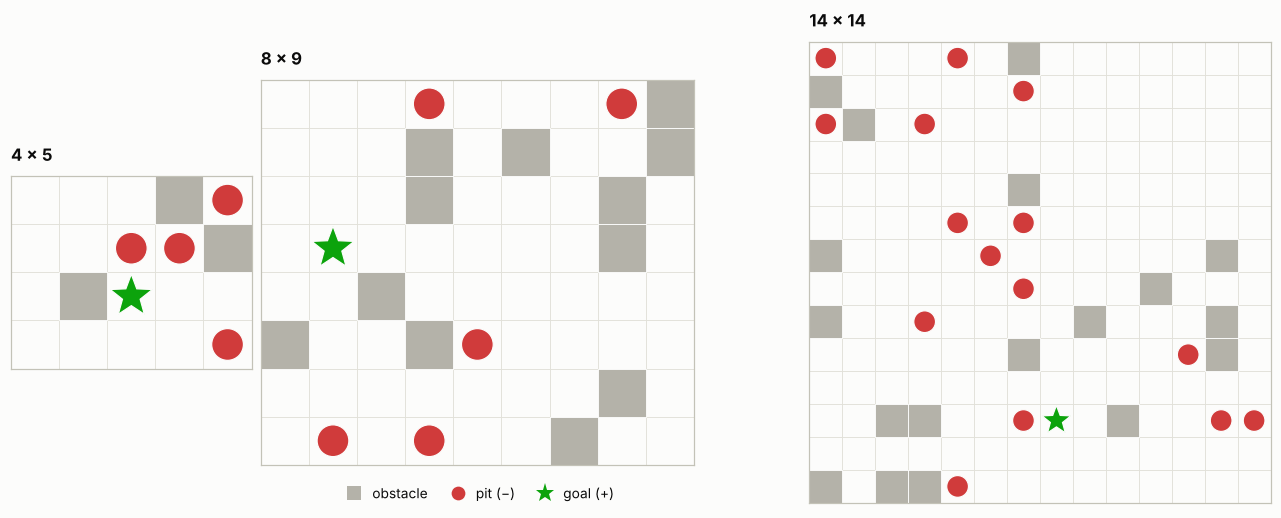

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.6), width_ratios=[5, 9, 14])
for ax, (rows, cols, seed) in zip(axes, [(4, 5, 5), (8, 9, 2), (14, 14, 3)]):
    world = ml.GridWorld.random(rows, cols, seed=seed)
    mp.plot_gridworld(world, ax=ax, title=f"{rows} × {cols}", legend=rows == 8)
mp.savefig(fig, "01_random_worlds");

### The world of Figure 1, recovered from the image

The report's first figure shows one particular 7 × 8 world together with the policies found for
it. Since the world was random and the seed is gone, the only way to get it back is to read it off
the picture. [`tools/digitize_report.py`](../tools/digitize_report.py) does that: it finds the
lattice of the drawing and classifies the colour at each node.

GridWorld(7x8, pits=4, obstacles=9, goal=(3, 6))


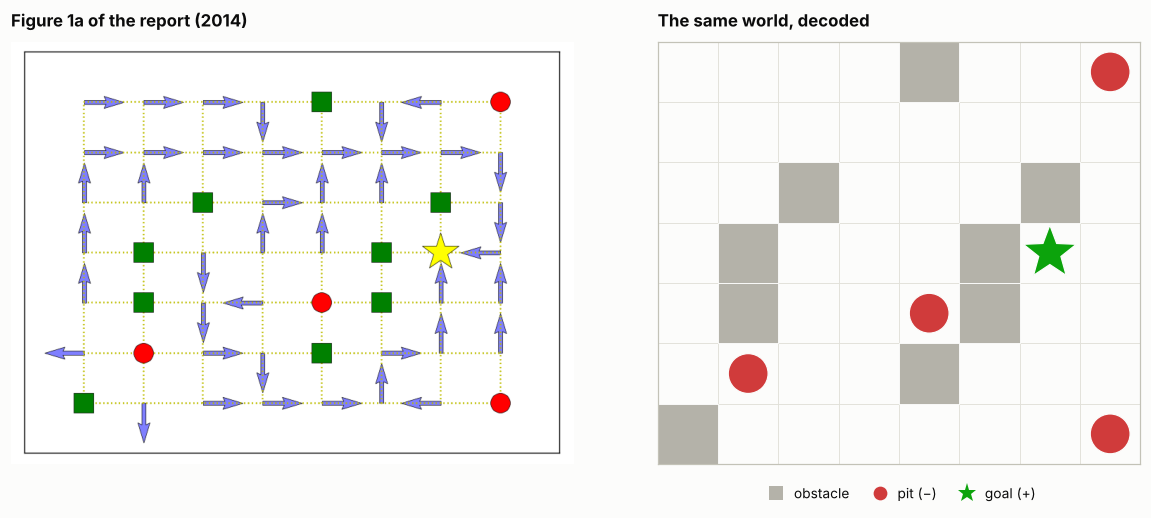

In [3]:
fig1_world = ml.GridWorld.report_figure1()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
mp.show_original("fig1a", axes[0], title="Figure 1a of the report (2014)")
mp.plot_gridworld(fig1_world, ax=axes[1], title="The same world, decoded")
print(fig1_world)

In the report's drawings green squares are obstacles, red discs are pits and the star is the goal;
the agent stands on the nodes of the lattice. Here cells are drawn as cells, obstacles are grey,
and green is kept for the goal. With nine obstacles and four pits this world has, as the report
says such worlds tend to, more obstacles than pits.

### What a move does

The 0.1 slips matter more than their size suggests, because the penalty for a pit is 20,000 times
the cost of a move. Take the cell in the bottom row, second from the left. It has an obstacle on
its left, a pit directly above and open floor to the right:

In [4]:
mdp = fig1_world.mdp
cell = fig1_world.state(6, 1)
P = mdp.P.toarray().reshape(mdp.n_states, 4, mdp.n_states)[cell]
outcomes = {
    "stays put": cell,
    "moves right": fig1_world.state(6, 2),
    "falls into the pit": fig1_world.state(5, 1),
}
moves = pd.DataFrame({name: P[:, s] for name, s in outcomes.items()}, index=[f"aim {a}" for a in ARROWS])
moves["expected reward"] = mdp.R[cell]
moves

,stays put,moves right,falls into the pit,expected reward
aim ↑,0.100,0.100,0.800,-160.002
aim →,0.100,0.800,0.100,-20.009
aim ↓,0.900,0.100,0.000,-0.010
aim ←,0.900,0.000,0.100,-20.009


Aiming right gets the agent out of the corner four times in five, but one time in ten it slips
into the pit. Aiming *down*, at the wall, can never end in the pit: the agent just stands there
until a slip carries it to the right, which takes ten moves on average and costs ten cents. Any
planner that takes the rewards seriously will choose to wait. Notebook 2 shows that it does, and
notebook 3 that this corner is exactly where the 2014 Q-learner went wrong.

### How often is the goal out of reach?

Because nothing guarantees a path to the goal, some free cells are walled in by obstacles and pits.
This turns out to drive one of the report's more puzzling plots (notebook 6), so it is worth
knowing how common it is.

In [5]:
rng = np.random.default_rng(0)
sizes = [(3, 3), (5, 5), (7, 8), (10, 10), (15, 15), (20, 20), (30, 30), (39, 39)]
rows_out = []
for rows, cols in sizes:
    pits, obstacles, cut_off, any_cut = [], [], [], []
    for _ in range(300):
        w = ml.GridWorld.random(rows, cols, seed=rng)
        free = w.free
        unreachable = free & ~w.connected_to_goal()
        pits.append(w.mask(PIT).mean())
        obstacles.append(w.mask(OBSTACLE).mean())
        cut_off.append(unreachable.sum() / max(free.sum(), 1))
        any_cut.append(unreachable.any())
    rows_out.append((f"{rows} × {cols}", rows * cols, np.mean(pits), np.mean(obstacles), np.mean(cut_off), np.mean(any_cut)))
pd.DataFrame(
    rows_out,
    columns=["world", "states", "share of pits", "share of obstacles", "free cells cut off from the goal", "worlds with a cut-off cell"],
).set_index("world")

,states,share of pits,share of obstacles,free cells cut off from the goal,worlds with a cut-off cell
world,,,,,
3 × 3,9,0.084,0.091,0.058,0.120
5 × 5,25,0.085,0.096,0.069,0.227
7 × 8,56,0.092,0.097,0.041,0.273
10 × 10,100,0.091,0.101,0.027,0.427
15 × 15,225,0.089,0.100,0.021,0.533
20 × 20,400,0.090,0.100,0.005,0.630
30 × 30,900,0.091,0.100,0.007,0.817
39 × 39,1521,0.090,0.100,0.007,0.937


Pits come out a little under 10% and obstacles at 10%, as the report describes. Only a few percent
of free cells are cut off from the goal, but in a large world there is almost always at least one.

## The crazy elevator

A building has $N$ floors, numbered from 0. The elevator has lost its mind: on floor $k$, pressing
the button for floor $a$ takes you to floor $j$ with probability

$$T(k, a, j) \;=\; Z_{k,a}\,\bigl|\sin\bigl(k + \sin(k\,a + \sin(j^2))\bigr)\bigr| ,$$

where $Z_{k,a}$ makes the probabilities sum to one over $j$. Arriving on floor $j$ costs $j$,
except for the ground floor, which pays $20N$ and ends the ride. There is one state per floor and
one action per button, so unlike the grid world, with its four moves, the elevator has as many
actions as states.

That is the formula as the report prints it. The report also shows two of the resulting
distributions for a 50-floor building (its Figure 5). The bar heights can be read back off that
figure and compared with the formula.

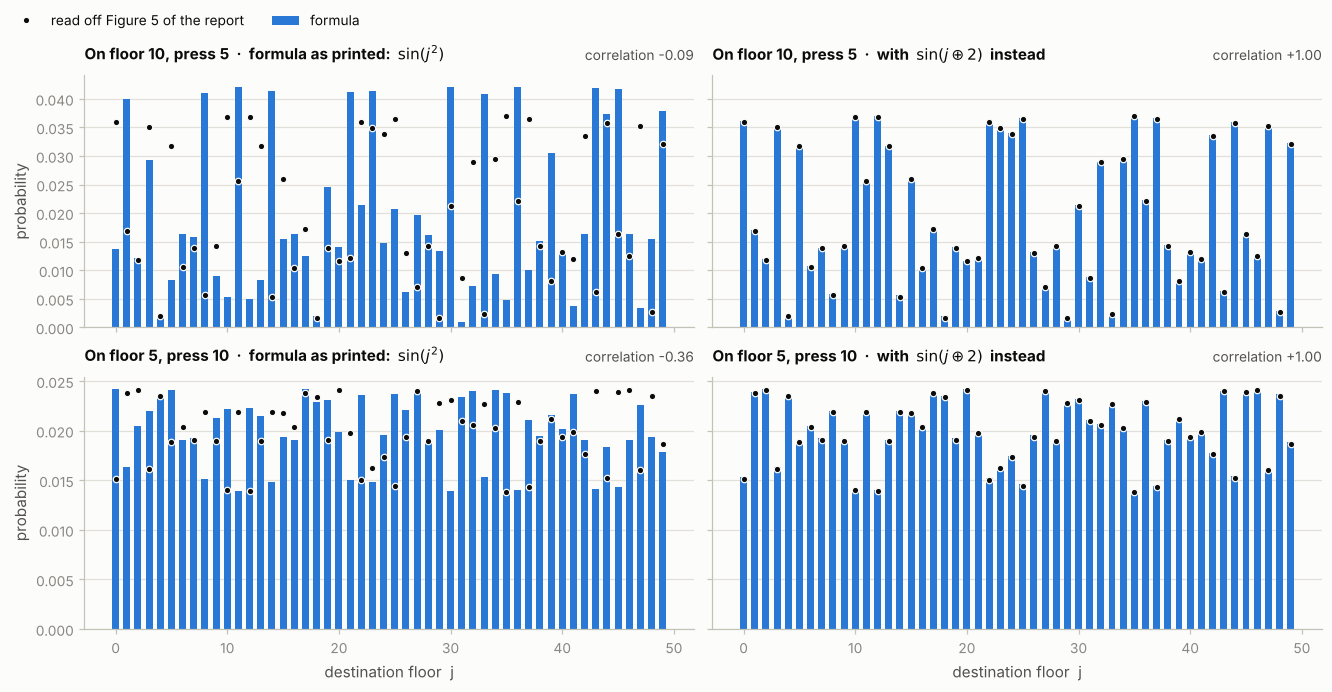

In [6]:
fig5 = report.figure5()
panels = [("p_from10_button5", 10, 5), ("p_from5_button10", 5, 10)]
formulas = [("as_written", r"formula as printed:  $\sin(j^2)$"), ("as_run", r"with  $\sin(j \oplus 2)$  instead")]

fig, axes = plt.subplots(2, 2, figsize=(12, 6.2), sharex=True, sharey="row")
for row, (column, k, a) in enumerate(panels):
    for col, (formula, label) in enumerate(formulas):
        ax = axes[row, col]
        T = ml.elevator_transitions(50, formula=formula)
        ax.bar(np.arange(50), T[k, a], width=0.62, color=mp.SERIES[0], label="formula")
        ax.plot(np.arange(50), fig5[column], "o", color=mp.INK, markersize=4.2, markeredgewidth=0.8, label="read off Figure 5 of the report")
        r = np.corrcoef(fig5[column], T[k, a])[0, 1]
        ax.set_title(f"On floor {k}, press {a}  ·  {label}", fontsize=10)
        ax.set_title(f"correlation {r:+.2f}", loc="right", fontsize=9, fontweight="normal", color=mp.INK_SECONDARY)
        ax.grid(axis="x", visible=False)
        if col == 0:
            ax.set_ylabel("probability")
        if row == 1:
            ax.set_xlabel("destination floor  j")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper left", ncol=2)
mp.savefig(fig, "01_elevator_formula");

### A caret that is not a power

The formula as printed (left) does not produce the published distributions. Replacing $j^2$ by
$j \oplus 2$, the bitwise exclusive-or of $j$ and 2, reproduces all hundred bars to within the
precision of the image (right).

The explanation is a classic Python slip. In Python `j ** 2` squares a number, while `j ^ 2` flips
its second-lowest bit, which swaps neighbouring pairs of integers:

In [7]:
j = np.arange(12)
pd.DataFrame({"j ** 2": j**2, "j ^ 2": j ^ 2}, index=pd.Index(j, name="j")).T

j,0,1,2,3,4,5,6,7,8,9,10,11
j ** 2,0,1,4,9,16,25,36,49,64,81,100,121
j ^ 2,2,3,0,1,6,7,4,5,10,11,8,9


So the code evidently contained `sin(j ^ 2)`, and the report describes what it was meant to say.
A second, independent check settles it. The report prints the optimal policy it found for 50
floors, the best button for every floor. That list can be compared with the optimal policy of each
version of the elevator.

In [8]:
max_diff = {f: max(np.abs(fig5[c] - ml.elevator_transitions(50, formula=f)[k, a]).max() for c, k, a in panels) for f, _ in formulas}
matches = {}
for formula, _ in formulas:
    policy = ml.value_iteration(ml.crazy_elevator(50, formula=formula), tol=1e-10).policy
    matches[formula] = int((policy[1:] == ml.REPORT_POLICY_50[1:]).sum())

display(Markdown(
    f"| elevator | largest gap to the bars of Figure 5 | floors (of 49) where the optimal button equals the report's |\n"
    f"|---|---|---|\n"
    f"| as written, `sin(j ** 2)` | {max_diff['as_written']:.4f} | {matches['as_written']} |\n"
    f"| as run, `sin(j ^ 2)` | {max_diff['as_run']:.4f} | {matches['as_run']} |"
))

| elevator | largest gap to the bars of Figure 5 | floors (of 49) where the optimal button equals the report's |
|---|---|---|
| as written, `sin(j ** 2)` | 0.0386 | 1 |
| as run, `sin(j ^ 2)` | 0.0002 | 49 |

With `j ^ 2` the rebuilt elevator returns the report's policy on every floor. With `j ** 2` it
agrees on a single floor, which is what chance would give.

Nothing of substance hangs on this. The formula was never meant to model anything; it was chosen to
be arbitrary, and exclusive-or makes it no less so. But they are two different MDPs, and only one
of them is the MDP of the report. From here on:

* `crazy_elevator(N)` is the elevator **as run** in 2014 (`formula="as_run"`, the default), so that
  the published numbers can be checked;
* `crazy_elevator(N, formula="as_written")` is the elevator the text describes. Notebook 4 repeats
  the main experiments on it and finds the same conclusions.

### Three floors, in full

The report's Figure 6 draws the complete state-action diagram of a three-floor building. Its
eighteen transition probabilities are easier to read as a table. Rows are (floor, button), columns
are where you end up. Arriving at 1 costs 1 and at 2 costs 2; arriving at 0 pays $20N = 60$ (the
diagram is labelled with the 50-floor prize of 1000).

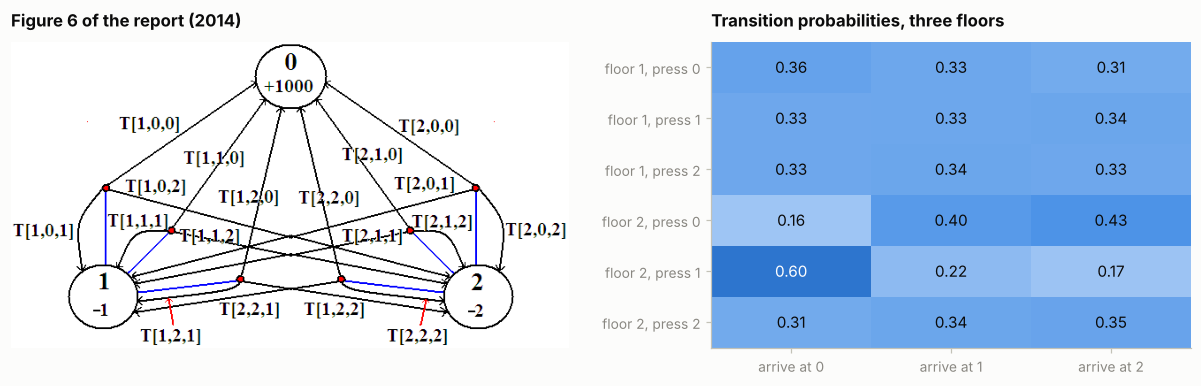

In [9]:
T3 = ml.elevator_transitions(3)
table3 = pd.DataFrame(
    T3[1:].reshape(6, 3),
    index=pd.MultiIndex.from_product([[1, 2], [0, 1, 2]], names=["on floor", "press"]),
    columns=pd.Index([0, 1, 2], name="arrive at"),
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), width_ratios=[1.25, 1])
mp.show_original("fig6", axes[0], title="Figure 6 of the report (2014)")
ax = axes[1]
image = ax.imshow(table3.values, cmap=mp.SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
for (r, c), p in np.ndenumerate(table3.values):
    ax.text(c, r, f"{p:.2f}", ha="center", va="center", color="white" if p > 0.5 else mp.INK, fontsize=10)
ax.set_xticks(range(3), [f"arrive at {j}" for j in range(3)])
ax.set_yticks(range(6), [f"floor {k}, press {a}" for k, a in table3.index])
ax.grid(False)
ax.set_title("Transition probabilities, three floors");

## Two very different problems

The report chose these two because they stress planners and learners in different ways. A few
numbers make the contrast concrete. The last three columns describe an agent that picks its
actions uniformly at random.

In [10]:
def describe(mdp, label, goal_mask):
    P = mdp.P.toarray() if mdp.is_sparse else mdp.P
    active_rows = np.repeat(mdp.active, mdp.n_actions)
    random_policy = ml.uniform_random_policy(mdp)
    info = ml.absorption(mdp, random_policy)
    p_goal = ml.hitting_probability(mdp, random_policy, goal_mask)
    return {
        "MDP": label,
        "states": mdp.n_states,
        "actions": mdp.n_actions,
        "outcomes per action": (P[active_rows] > 0).sum(axis=1).mean(),
        "P(reaches the goal)": p_goal[mdp.active].mean(),
        "P(episode ends)": info.probability[mdp.active].mean(),
        "moves until it ends": np.mean(info.steps[mdp.active]),
    }


rows_out = [describe(fig1_world.mdp, "grid world 7 × 8 (Figure 1)", fig1_world.mask(GOAL))]
world3 = report.figure3_gridworld()
rows_out.append(describe(world3.mdp, "grid world 39 × 39 (Figure 3)", world3.mask(GOAL)))
for n in (10, 50):
    elevator = ml.crazy_elevator(n)
    rows_out.append(describe(elevator, f"crazy elevator, {n} floors", elevator.terminal))
pd.DataFrame(rows_out).set_index("MDP")

,states,actions,outcomes per action,P(reaches the goal),P(episode ends),moves until it ends
MDP,,,,,,
grid world 7 × 8 (Figure 1),56,4,2.845,0.111,1.000,36.147
grid world 39 × 39 (Figure 3),1521,4,2.957,0.006,1.000,20.700
"crazy elevator, 10 floors",10,10,10.000,1.000,1.000,9.895
"crazy elevator, 50 floors",50,50,50.000,1.000,1.000,47.872


* In the grid world an action has at most three outcomes, all of them next door, so information
  about the goal has to travel across the grid one cell per sweep. Acting at random is hopeless:
  the walk finds the goal one time in nine in the small world and almost never in the large one.
  Every other time it ends in a pit.
* In the elevator every button can lead to every floor. Nothing is far from anything, the ride
  always ends at the ground floor, and a random button-pusher needs about as many presses as there
  are floors. What is hard here is the sheer number of state-action pairs, $N^2$, each with a
  noisy outcome.

The next three notebooks reproduce the report's experiments on these two families:
[2 · planning on the grid world](02_gridworld_planning.ipynb),
[3 · Q-learning on the grid world](03_gridworld_q_learning.ipynb) and
[4 · the crazy elevator](04_crazy_elevator.ipynb).